# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** The goal of this study is to predict whether a breast mass is malignant or benign using 30 numerical measurements of cell nuclei obtained from digitized images. This is a supervised binary classification problem because the dataset contains labeled examples with two possible outcomes. A false negative, which means predicting a malignant mass as benign, is more costly because it may delay proper diagnosis and treatment. The model's success will be evaluated using accuracy, a confusion matrix, and especially recall for malignant cases to ensure that as many cancerous masses as possible are correctly identified.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

try:
    display
except NameError:
    display = print

A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [6]:
# TODO: load the dataset and copy its DataFrame into df
# Load the dataset
data = load_breast_cancer(as_frame=True)

# Copy the DataFrame into df
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign
Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [7]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
# Print the dataset dimensions
print("Shape:", df.shape)

# Count each data type
print("\nCounts of each data type:")
print(df.dtypes.value_counts())

# Show the first 5 rows
print("\nFirst 5 rows:")
display(df.head())

Shape: (569, 31)

Counts of each data type:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [8]:
# TODO: class counts and percentages
# Count each class
class_counts = df["target"].value_counts().sort_index()

# Calculate the proportion of each class
class_proportions = df["target"].value_counts(normalize=True).sort_index()

# Print the counts and percentages
print("Class Counts:")
print(class_counts.rename(index={0: "Malignant", 1: "Benign"}))

print("\nClass Proportions:")
print((class_proportions * 100).rename(index={0: "Malignant", 1: "Benign"}).round(2).astype(str) + "%")

Class Counts:
target
Malignant    212
Benign       357
Name: count, dtype: int64

Class Proportions:
target
Malignant    37.26%
Benign       62.74%
Name: proportion, dtype: object


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [9]:
# TODO: describe().T, then the 10 largest skewness values
# Select the features, excluding the target column
features = df.drop(columns=["target"])

# Display summary statistics with features as rows
print("Summary Statistics:")
display(features.describe().T)

# Find the 10 most skewed features
skewness = features.skew()
print("\n10 Most Skewed Features:")
display(skewness.loc[skewness.abs().sort_values(ascending=False).head(10).index])

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [10]:
# TODO: correlation with target, sorted
# Compute the correlation of every feature with the target
target_corr = df.corr(numeric_only=True)["target"].drop("target").sort_values()

# Display the 5 most negative correlations
print("5 Most Negative Correlations:")
display(target_corr.head(5))

# Display the 5 most positive correlations
print("\n5 Most Positive Correlations:")
display(target_corr.tail(5).sort_values(ascending=False))

5 Most Negative Correlations:


,target
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



5 Most Positive Correlations:


,target
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** The class proportions show that there are more benign cases than malignant cases, so accuracy alone may not be enough to evaluate the model. Recall for malignant cases should also be considered to check how well the model identifies cancerous masses. The skewness shows that some features have uneven distributions, so transformations may be needed to make the data more suitable for certain models, while scaling may help models that are sensitive to feature values.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

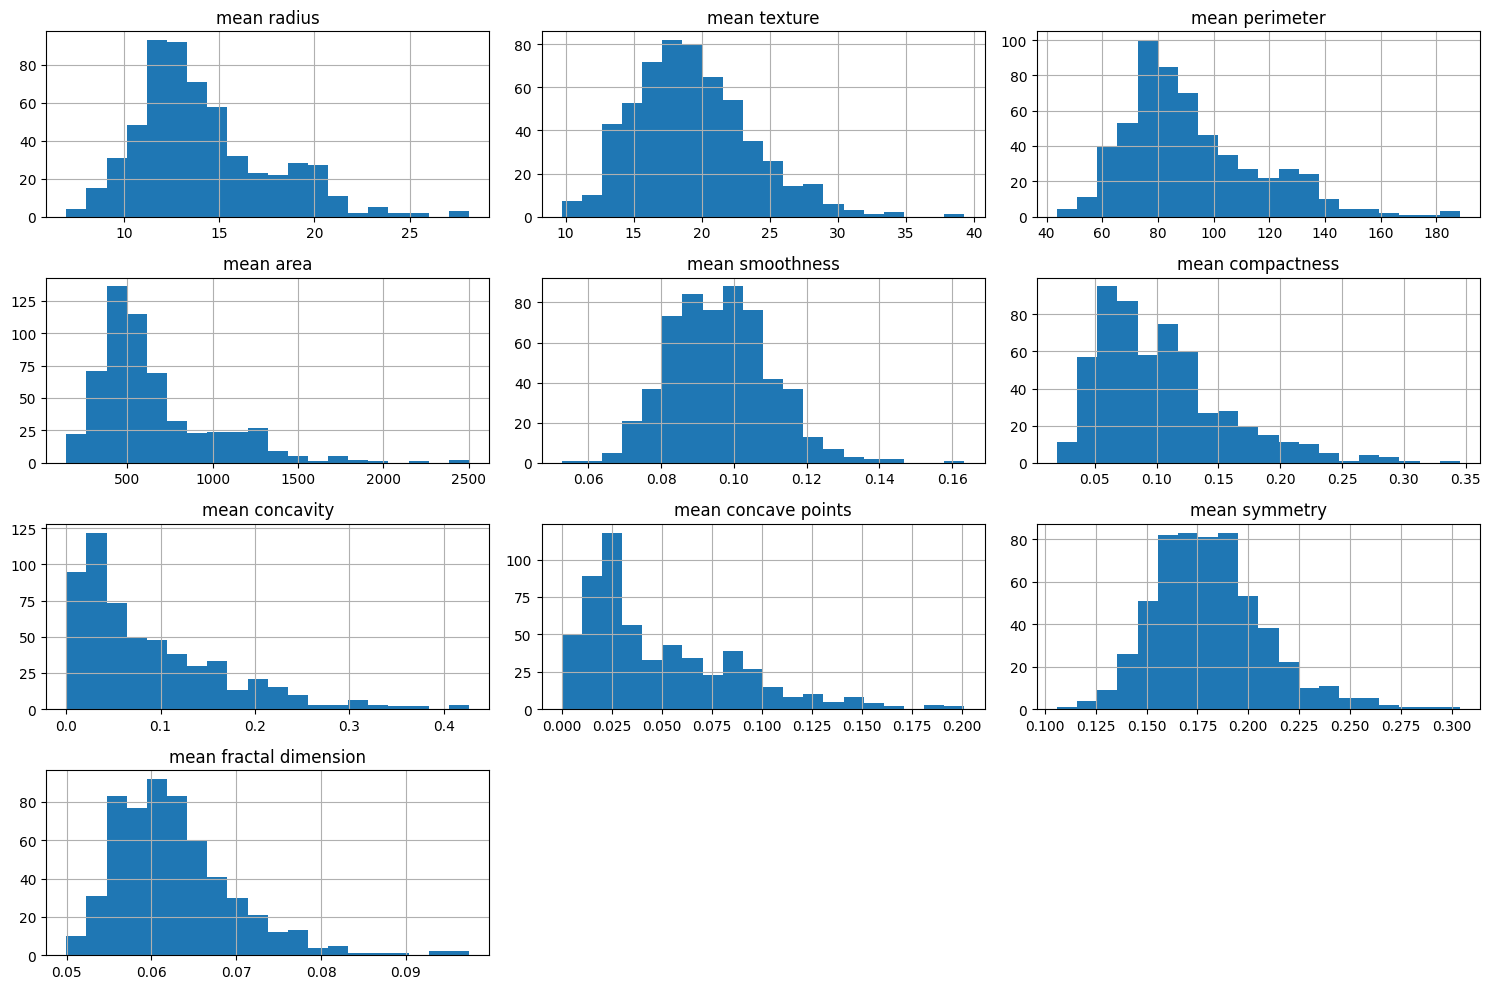

In [11]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
# Plot histograms of the ten mean features
df.filter(like="mean").hist(figsize=(15, 10), bins=20)

plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

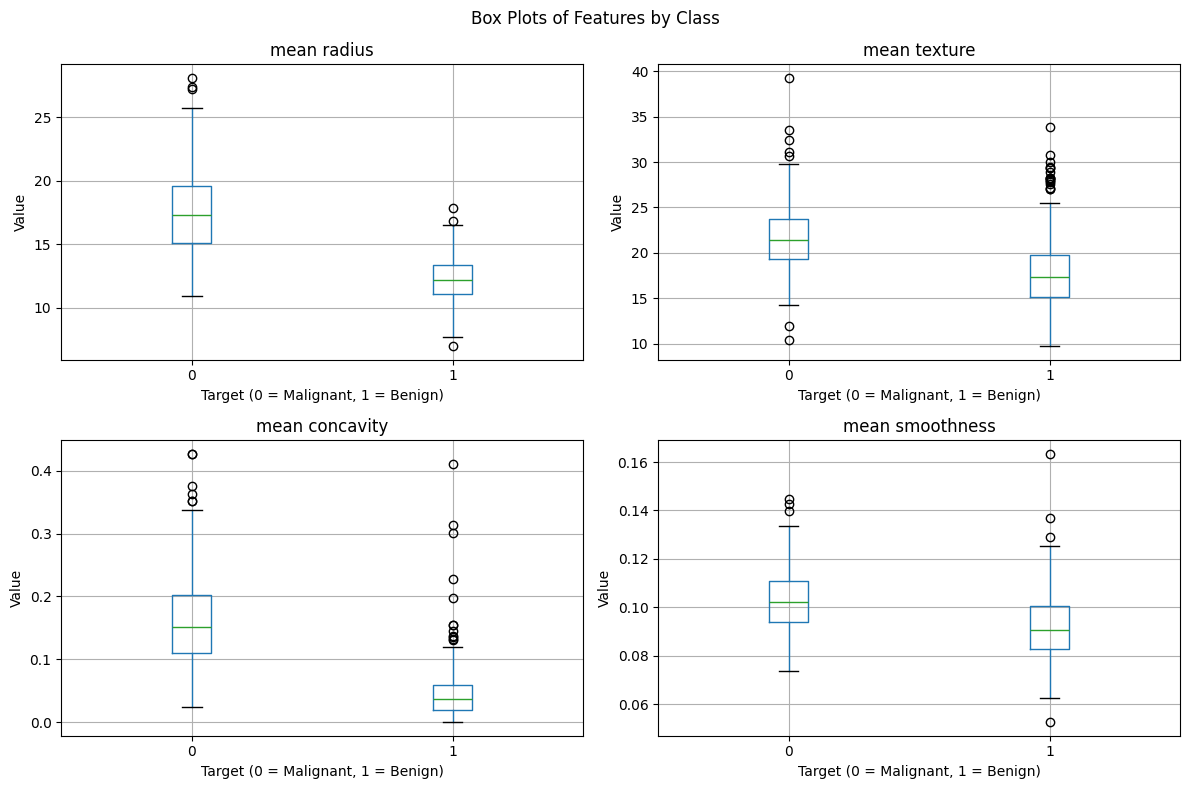

In [12]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
# Select the four features
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# Create one box plot per feature, grouped by target
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flat):
    df.boxplot(column=feature, by="target", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Target (0 = Malignant, 1 = Benign)")
    ax.set_ylabel("Value")

plt.suptitle("Box Plots of Features by Class")
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

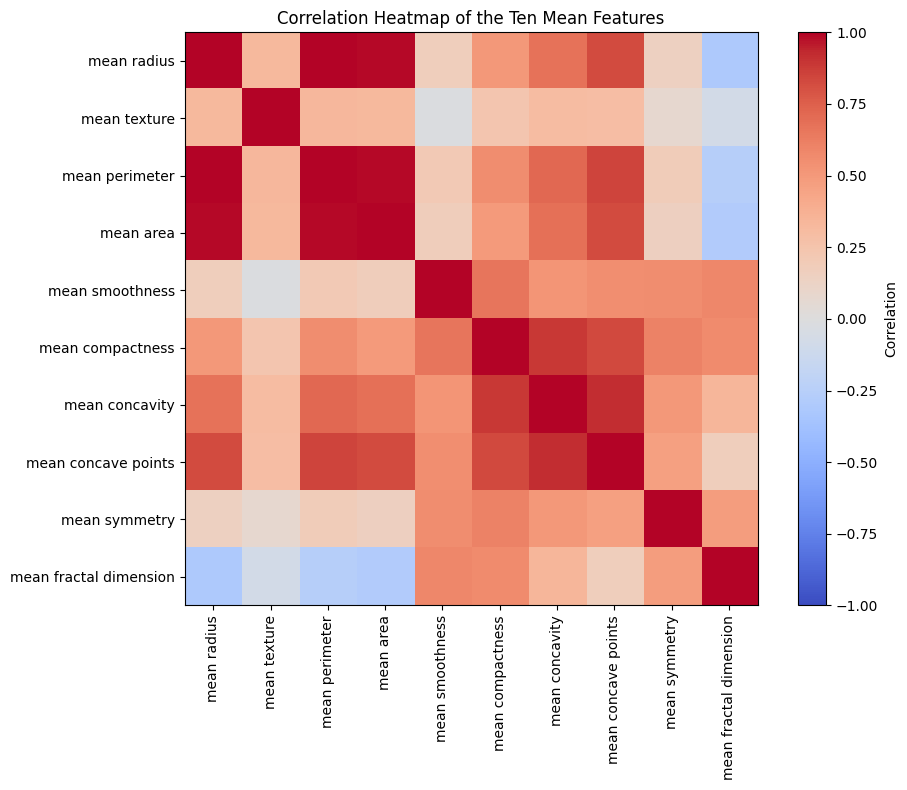

In [13]:
# TODO: correlation matrix of the "mean" features drawn with imshow
# Select the ten mean features
mean_features = df.filter(like="mean")

# Compute the correlation matrix
corr_matrix = mean_features.corr()

# Draw the correlation heatmap
plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Correlation Heatmap of the Ten Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

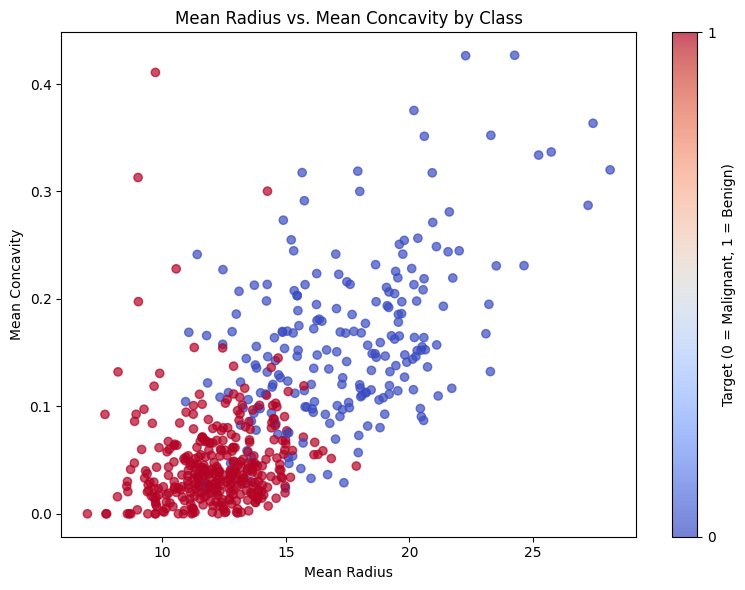

In [14]:
# TODO: coloured scatter plot with axis labels and a colourbar
# Scatter plot of mean radius against mean concavity
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.7
)

# Add axis labels and title
plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity by Class")

# Add colorbar
cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")
cbar.set_ticks([0, 1])

plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** The mean radius, mean perimeter, and mean area appear redundant because they are strongly related to each other. The mean radius and mean concavity separate malignant and benign cases more clearly, since malignant cases generally have higher values. Mean compactness and mean concave points may also help distinguish the two classes.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [15]:
# TODO: total missing values and duplicated rows
# Count missing values
print("Total missing values:", df.isnull().sum().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Separate features and target
X = df.drop(columns="target")
y = df["target"]

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [16]:
# TODO: IQR outlier count per feature
# Calculate Q1, Q3, and IQR for each feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

# Count outliers using the IQR rule
outlier_counts = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

# Display the 10 features with the most outliers
print("10 Features with the Most Outliers:")
display(outlier_counts.sort_values(ascending=False).head(10))

10 Features with the Most Outliers:


,0
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, I would not delete the outlying rows because they may represent actual differences in the breast mass measurements, not errors. Removing them could cause the loss of important information needed to distinguish malignant and benign cases. Instead, I would keep the data unless there is evidence that the values are incorrect.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [17]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
# Compute the absolute correlation matrix
corr_matrix = X.corr().abs()

# Keep only the upper triangle to compare each feature with earlier features
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with absolute correlation above 0.95
high_corr = upper_triangle.stack()
high_corr = high_corr[high_corr > 0.95]

print("Feature pairs with absolute correlation above 0.95:")
display(high_corr)

Feature pairs with absolute correlation above 0.95:


mean radius      mean perimeter     0.997855
                 mean area          0.987357
                 worst radius       0.969539
                 worst perimeter    0.965137
mean perimeter   mean area          0.986507
                 worst radius       0.969476
                 worst perimeter    0.970387
mean area        worst radius       0.962746
                 worst perimeter    0.959120
                 worst area         0.959213
radius error     perimeter error    0.972794
                 area error         0.951830
worst radius     worst perimeter    0.993708
                 worst area         0.984015
worst perimeter  worst area         0.977578
dtype: float64

**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [18]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
# Fit SelectKBest to select the 10 best features
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

# Build a Series of feature scores and sort them
feature_scores = pd.Series(selector.scores_, index=X.columns)
feature_scores = feature_scores.sort_values(ascending=False)

# Display the top 10 features
print("Top 10 Features Based on SelectKBest:")
display(feature_scores.head(10))

Top 10 Features Based on SelectKBest:


,0
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [19]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
# Standardize the features
X_scaled = StandardScaler().fit_transform(X)

# Apply Recursive Feature Elimination using Logistic Regression
rfe = RFE(
    estimator=LogisticRegression(max_iter=10000),
    n_features_to_select=10
)
rfe.fit(X_scaled, y)

# Store the names of the selected features
rfe_features = X.columns[rfe.support_].tolist()

print("Selected 10 Features:")
display(rfe_features)

Selected 10 Features:


['mean concave points',
 'radius error',
 'area error',
 'compactness error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst concavity',
 'worst concave points']

**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

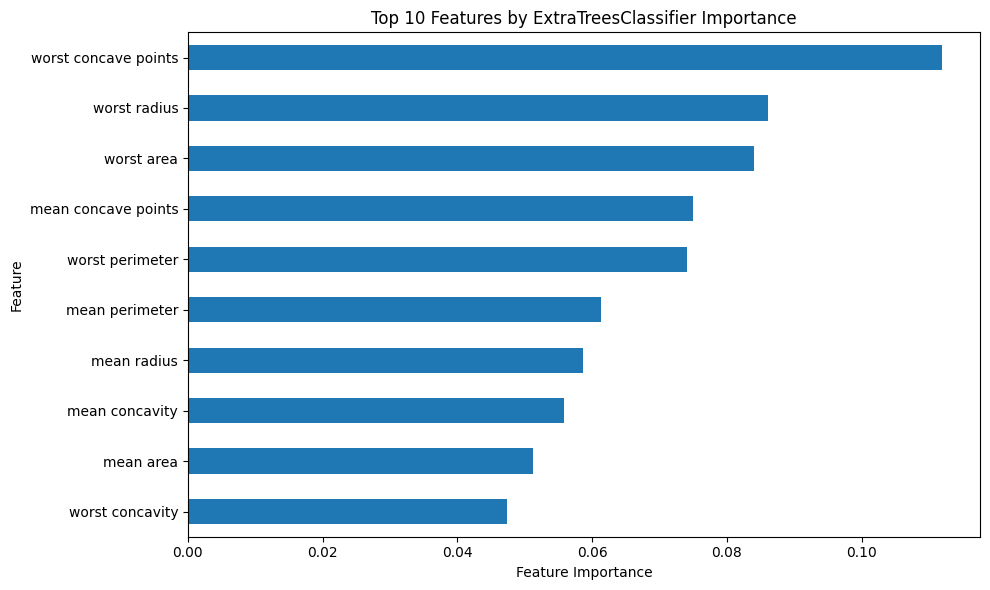

In [20]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
# Fit ExtraTreesClassifier
model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)

# Store and rank feature importances
imp = pd.Series(model.feature_importances_, index=X.columns)
imp = imp.sort_values(ascending=False)

# Plot the top 10 features
top10 = imp.head(10).sort_values()

plt.figure(figsize=(10, 6))
top10.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features by ExtraTreesClassifier Importance")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [21]:
# TODO: vote across the three methods
# Get the top 10 features from each method
kbest_features = X.columns[selector.get_support()].tolist()
extra_trees_features = imp.head(10).index.tolist()

# Vote across the three methods
selected = [
    feature for feature in X.columns
    if sum(feature in method_features for method_features in [
        kbest_features, rfe_features, extra_trees_features
    ]) >= 2
]

print("Selected Features:", selected)
print("Number of Selected Features:", len(selected))

Selected Features: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Number of Selected Features: 10


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [22]:
# TODO: train_test_split with stratify=y
# Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

# Print the shapes of the training and testing sets
print(X_train.shape, X_test.shape)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)
(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [23]:
# TODO: fit both scalers on X_train and print the verifying statistics
# Create and fit both scalers using training data only
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)

# Convert scaled data back to DataFrames
X_train_standard = pd.DataFrame(
    X_train_standard, columns=X_train.columns, index=X_train.index
)
X_train_minmax = pd.DataFrame(
    X_train_minmax, columns=X_train.columns, index=X_train.index
)

# Select the first four features
first_four = X_train.columns[:4]

# Verify StandardScaler effect
print("StandardScaler: Mean and Standard Deviation")
print("Mean:")
display(X_train_standard[first_four].mean().round(4))
print("Standard Deviation:")
display(X_train_standard[first_four].std(ddof=0).round(4))

# Verify MinMaxScaler effect
print("\nMinMaxScaler: Minimum and Maximum")
print("Minimum:")
display(X_train_minmax[first_four].min().round(4))
print("Maximum:")
display(X_train_minmax[first_four].max().round(4))

StandardScaler: Mean and Standard Deviation
Mean:


,0
mean radius,0.0
mean texture,-0.0
mean perimeter,-0.0
mean area,-0.0


Standard Deviation:


,0
mean radius,1.0
mean texture,1.0
mean perimeter,1.0
mean area,1.0



MinMaxScaler: Minimum and Maximum
Minimum:


,0
mean radius,0.0
mean texture,0.0
mean perimeter,0.0
mean area,0.0


Maximum:


,0
mean radius,1.0
mean texture,1.0
mean perimeter,1.0
mean area,1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [24]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
# Fit PCA on the standardized training data
pca = PCA()
pca.fit(X_train_standard)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components needed to retain 95% variance
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Principal components needed to retain 95% variance:", n_components_95)
print("Cumulative explained variance:", round(cumulative_variance[n_components_95 - 1], 4))

Principal components needed to retain 95% variance: 10
Cumulative explained variance: 0.956


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [25]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# Define the six candidate models
models = {
    "LR": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [26]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
# Run spot-check on all features using raw and scaled data
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Build a DataFrame with mean accuracies
summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

# Display the results
display(summary.round(4))

,raw,scaled
LR,0.9450,0.9823
LDA,0.9472,0.9472
KNN,0.9229,0.9649
CART,0.9276,0.9276
NB,0.9341,0.9320
SVM,0.8987,0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** KNN and SVM benefit the most from scaling because they depend on distances between data points or the size of feature values. Logistic Regression and LDA may also benefit because scaling helps them work with features that have different ranges. Decision Trees and Gaussian Naive Bayes are generally less affected by scaling because they do not rely on distance calculations.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [27]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
# Run spot-check using selected features with scaling
selected_results = spot_check(models, X_train[selected], scale=True)

# Compare selected-feature results with all-feature scaled results
selection_summary = pd.DataFrame({
    "All Features (Scaled)": summary["scaled"],
    "Selected Features (Scaled)": {
        name: scores.mean()
        for name, scores in selected_results.items()
    }
})

# Calculate the difference in accuracy
selection_summary["Difference"] = (
    selection_summary["Selected Features (Scaled)"]
    - selection_summary["All Features (Scaled)"]
)

display(selection_summary.round(4))

,All Features (Scaled),Selected Features (Scaled),Difference
LR,0.9823,0.9604,-0.0219
LDA,0.9472,0.9430,-0.0043
KNN,0.9649,0.9428,-0.0221
CART,0.9276,0.9210,-0.0066
NB,0.9320,0.9517,0.0197
SVM,0.9758,0.9539,-0.0219


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

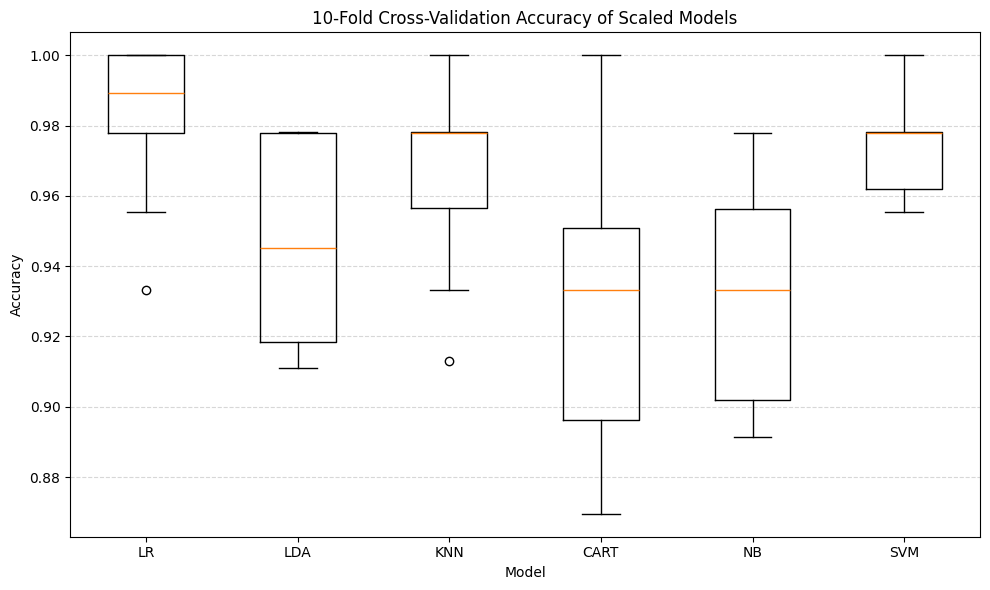

In [28]:
# TODO: box plot of the 10 fold scores per model
# Prepare the 10-fold accuracy scores of the scaled models
scaled_scores = [scaled_results[name] for name in scaled_results.keys()]

# Plot a box plot for each model
plt.figure(figsize=(10, 6))
plt.boxplot(scaled_scores, labels=list(scaled_results.keys()))

plt.title("10-Fold Cross-Validation Accuracy of Scaled Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [29]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
# Find the best scaled model based on mean accuracy
best_model_name = max(
    scaled_results,
    key=lambda name: scaled_results[name].mean()
)

print("Best scaled model:", best_model_name)

# Create a pipeline with scaling
best_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", models[best_model_name])
])

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

# Cross-validate the best model
cv_results = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

# Display the mean scores
print("\nCross-Validation Results:")
for metric in scoring:
    print(f"{metric}: {cv_results['test_' + metric].mean():.4f}")

Best scaled model: LR

Cross-Validation Results:
accuracy: 0.9823
roc_auc: 0.9922
recall_malignant: 0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [30]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
# Create a scaling pipeline with SVM
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

# Define the parameter grid
param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

# Run GridSearchCV on the training data
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Display the best parameters and cross-validation accuracy
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search.best_score_, 4))

Best Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best Cross-Validation Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [31]:
# Create a scaling pipeline with KNN
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

# Define the parameter grid
param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

# Run GridSearchCV on the training data
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid_search.fit(X_train, y_train)

# Display the best parameters and cross-validation accuracy
print("Best Parameters:", knn_grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(knn_grid_search.best_score_, 4))

Best Parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best Cross-Validation Accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [32]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
# Import the required ensemble models
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.model_selection import StratifiedKFold

# Set up stratified 10-fold cross-validation
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# Define the four ensemble methods
ensembles = {
    "Random Forest": RandomForestClassifier(random_state=seed),
    "Extra Trees": ExtraTreesClassifier(random_state=seed),
    "Gradient Boosting": GradientBoostingClassifier(random_state=seed),
    "AdaBoost": AdaBoostClassifier(random_state=seed)
}

# Cross-validate the four ensemble methods
ensemble_results = spot_check(ensembles, X_train, scale=False)

# Create a hard VotingClassifier using the tuned SVM, tuned KNN, and Random Forest
voting_model = VotingClassifier(
    estimators=[
        ("svm", grid_search.best_estimator_),
        ("knn", knn_grid_search.best_estimator_),
        ("rf", ensembles["Random Forest"])
    ],
    voting="hard"
)

# Cross-validate the voting ensemble
voting_results = spot_check(
    {"Voting": voting_model},
    X_train,
    scale=False
)

# Combine and compare the mean cross-validation accuracies
all_results = {**ensemble_results, **voting_results}

ensemble_summary = pd.Series({
    name: scores.mean()
    for name, scores in all_results.items()
}, name="Mean Accuracy")

ensemble_summary = ensemble_summary.sort_values(ascending=False)

print("Ensemble Model Comparison:")
display(ensemble_summary.to_frame().round(4))

Ensemble Model Comparison:


,Mean Accuracy
Voting,0.9781
Extra Trees,0.9736
Random Forest,0.9691
Gradient Boosting,0.9670
AdaBoost,0.9626


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [33]:
# TODO: leaderboard Series
# Build a leaderboard of the tuned models and ensemble models
leaderboard = pd.Series({
    "Tuned SVM": grid_search.best_score_,
    "Tuned KNN": knn_grid_search.best_score_,
    **{
        name: scores.mean()
        for name, scores in all_results.items()
    }
}, name="Mean CV Accuracy")

# Sort from highest to lowest accuracy
leaderboard = leaderboard.sort_values(ascending=False)

# Display the leaderboard
display(leaderboard.round(4))

,Mean CV Accuracy
Tuned SVM,0.9802
Voting,0.9781
Extra Trees,0.9736
Tuned KNN,0.9693
Random Forest,0.9691
Gradient Boosting,0.9670
AdaBoost,0.9626


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM
Mean CV Accuracy: 0.9802

Test Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



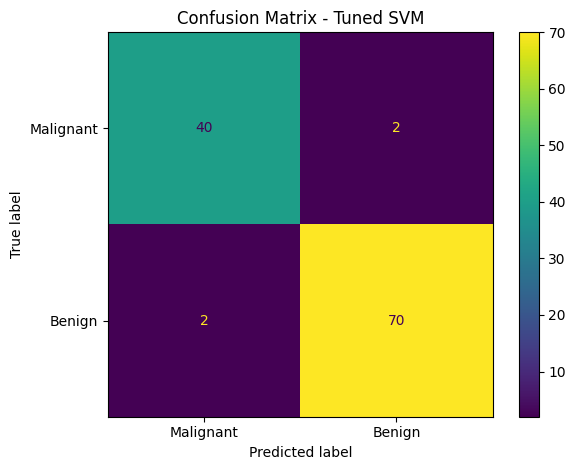

In [34]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Create a dictionary of all candidate models
candidate_models = {
    "Tuned SVM": grid_search.best_estimator_,
    "Tuned KNN": knn_grid_search.best_estimator_,
    **ensembles,
    "Voting": voting_model
}

# Select the model with the highest mean CV accuracy
winner_name = leaderboard.index[0]
winner_model = candidate_models[winner_name]

print("Winning Model:", winner_name)
print("Mean CV Accuracy:", round(leaderboard.iloc[0], 4))

# Fit the winning model on the full training set
winner_model.fit(X_train, y_train)

# Evaluate the model on the held-out test set
y_pred = winner_model.predict(X_test)

print("\nTest Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    zero_division=0
))

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Malignant", "Benign"]
)

plt.title(f"Confusion Matrix - {winner_name}")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [35]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
# Import joblib
import joblib

# Save the trained model
joblib.dump(winner_model, "breast_cancer_model.joblib")
print("Model saved successfully.")

# Reload the saved model
loaded_model = joblib.load("breast_cancer_model.joblib")
print("Model loaded successfully.")

# Generate predictions using the reloaded model
loaded_predictions = loaded_model.predict(X_test)

# Confirm that the reloaded model reproduces the original predictions
print(
    "Predictions match:",
    np.array_equal(y_pred, loaded_predictions)
)

# Compare the first 5 predictions with the actual test values
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:5].values,
    "Predicted": loaded_predictions[:5]
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

display(comparison)

Model saved successfully.
Model loaded successfully.
Predictions match: True


,Actual,Predicted,Correct
0,0,0,True
1,0,0,True
2,1,1,True
3,0,0,True
4,1,1,True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
- Feature selection using the whole dataset can inflate cross-validation scores because the model has already used information from the validation data to choose the features. To fix this, I would put feature selection inside a Pipeline so it is fitted only on the training part of each fold. This gives a more reliable estimate of the model's performance.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
- I would report recall for the malignant class because it measures how well the model identifies cancerous cases. Accuracy alone is not enough because a model can have high accuracy but still miss cancerous cases. I would also report ROC-AUC and the confusion matrix to better understand the model's performance.
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
- If two models differ by only 0.3% in cross-validation accuracy, I would compare their scores across the folds to see which performs more consistently. If their performance is similar, I would choose the model that is easier to understand, faster to train, and better at identifying malignant cases.
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
- With a much smaller dataset, the model's results may be less reliable because there are fewer examples to learn from. I would use stratified cross-validation and check how consistent the scores are. If the dataset is highly imbalanced, I would focus more on recall, precision, and F1-score instead of relying on accuracy alone.
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.
- I would repeat the workbook using the Iris dataset to predict the type of iris flower based on its measurements. Most steps, such as data exploration, visualization, splitting, scaling, feature selection, and model evaluation, would remain similar. However, since the Iris dataset has three classes, I would adjust the classification metrics, class labels, and confusion matrix to handle multiple classes.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [37]:
%cd /content/drive/MyDrive/IS110_BPerformance_Maravilla/IS110_repo_Maravilla

/content/drive/MyDrive/IS110_BPerformance_Maravilla/IS110_repo_Maravilla


In [38]:
!git config --global user.name 'louienapaulamaravilla-sys'
!git config --global user.email 'louienapaula.maravilla@students.isatu.edu.ph'

In [ ]:
!cp "/content/drive/MyDrive/ICT110_Maravilla/ML_Workbook_Wisconsin_Diagnostic.ipynb" ""

In [ ]:
!git add ICT110_Maravilla/ML_Workbook_Wisconsin_Diagnostic.ipynb

fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
